In [3]:
import pandas as pd
import numpy as np

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (0.5 * study_hours) + (0.3 * attendance) + (0.2 * previous_mark) + np.random.normal(0, 5, n)
df = pd.DataFrame({
'study_hours': study_hours,
'attendance': attendance,
'previous_mark': previous_mark,
'final_score': final_score
})

df.loc[0:5, 'study_hours'] = np.nan # Missing values
df.loc[99, 'study_hours'] = 50 # Outlier
df.loc[98, 'attendance'] = -10 # Impossible value

print(df)
df.to_csv('student_data.csv', index=False)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627
99    50.000000   73.570297      79.444433    46.414470

[100 rows x 4 columns]


Part A — Inspect and Clean
1. Identify the outlier in study_hours (the student with 50 hours). Remove or cap this value as you see fit. Justify your choice.

- The Value of study_hours > 24 is removed instead of capping the value, because 50 hours of study is not possible
  
- There are missing input values from index 0-5 and rows with negative inputs. For the negative inputs and missing input values I have assigned their value to be missing value and then I will find the mean and median, if there is high variation I will use the median value for these missing inputs and if the dataset is symmetrical I will use the mean value for the unassigned or missing values
  
2. What is the shape of the feature matrix? Which columns are numerical? Which column is your target variable?

- Feature matrix shape is (99,3) with 99 input values of the students and 3 features that are study_hours, attendance and previous_mark
-  All four columns are numerical that are the study_hours, attendance, previous_mark and final_score
-  final_score is the target

In [4]:
df = df[df['study_hours'] != 50]

In [5]:
print(df)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227  -10.000000      82.192932    44.045627

[99 rows x 4 columns]


In [121]:
print(df.drop(columns="final_score").shape)

(99, 3)


In [40]:
df.loc[df["study_hours"] < 0, "study_hours"] = np.nan
df.loc[df["attendance"] < 0, "attendance"] = np.nan

In [7]:
print(df)

    study_hours  attendance  previous_mark  final_score
0           NaN   70.846293      75.366810    35.178989
1           NaN   80.793547      78.411768    39.481248
2           NaN   81.572855      86.245769    48.605167
3           NaN   76.977227      85.807031    47.329456
4           NaN   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227         NaN      82.192932    44.045627

[99 rows x 4 columns]


Part B — Summarize

1. Calculate the mean, median, and standard deviation for all columns.
2. Write 3 observations in plain English. Example: "The standard deviation of attendance is low, suggesting that most students maintain a consistent
attendance rate."
- Previous mark variation is higher than the other features which means some students scored a very high score and some students scored very low
- Students are 1.71 hours afar from the average study hours which is 4.79 so most students study between 3.08 hours and 6.5hours
- The values of the mean and median are almost the same which makes our dataset almost symmeteric

In [51]:
print("study_hours mean: " ,df["study_hours"].mean().round(2))
print("study_hours median: " ,df["study_hours"].median().round(2))
print("study_hours std: " ,df["study_hours"].std().round(2))
print()
print("attendance mean: " ,df["attendance"].mean().round(2))
print("attendance median: " ,df["attendance"].median().round(2))
print("attendance std: " ,df["attendance"].std().round(2))
print()
print("previous_mark mean: " ,df["previous_mark"].mean().round(2))
print("previous_mark median: " ,df["previous_mark"].median().round(2))
print("previous_mark std: " ,df["previous_mark"].std().round(2))
print()
print("final_score mean: " ,df["final_score"].mean().round(2))
print("final_score median: " ,df["final_score"].median().round(2))
print("final_score std: " ,df["final_score"].std().round(2))

study_hours mean:  4.79
study_hours median:  4.79
study_hours std:  1.71

attendance mean:  85.34
attendance median:  86.0
attendance std:  9.51

previous_mark mean:  70.89
previous_mark median:  71.23
previous_mark std:  16.32

final_score mean:  42.65
final_score median:  42.67
final_score std:  6.11


In [21]:
df['study_hours'] = df['study_hours'].fillna(df['study_hours'].mean())
df['attendance'] = df['attendance'].fillna(df['attendance'].mean())

In [22]:
print(df.isna().sum())
print(df.drop(columns="final_score").shape) 

study_hours      0
attendance       0
previous_mark    0
final_score      0
dtype: int64
(99, 3)


Part C — Visualize

1. Create a histogram for final_score.
2. Create a scatter plot of study_hours vs final_score. Describe the trend.

- The scatter plot shows a weak positive trend, students who study more hours score only slitghtly higher on average and the points are spreaded which means study hours don't predict the final score alone

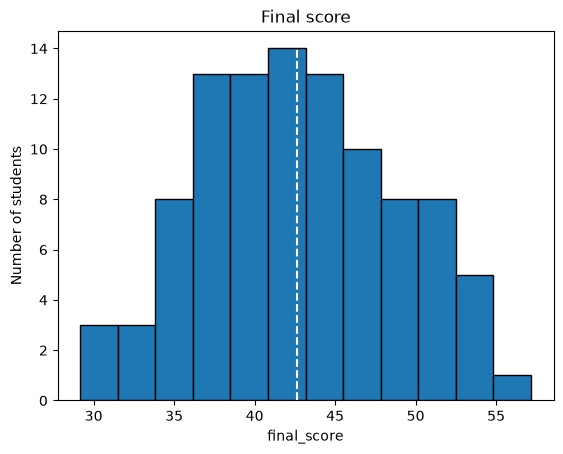

In [23]:
import numpy as np
import matplotlib.pyplot as plt

plt.hist(df["final_score"], bins=12, edgecolor="black")
plt.axvline(df["final_score"].mean(), color="white", linestyle="--")
plt.title("Final score")
plt.xlabel("final_score")
plt.ylabel("Number of students")
plt.show()

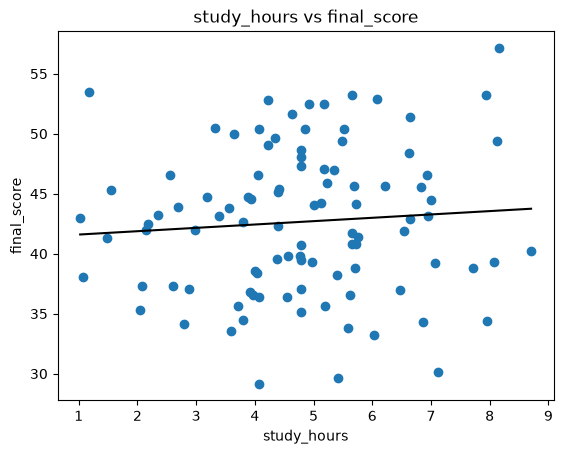

In [24]:
import numpy as np
import matplotlib.pyplot as plt

plt.scatter(df["study_hours"], df["final_score"])

slope, intercept = np.polyfit(df["study_hours"], df["final_score"], 1)
xs = np.linspace(df["study_hours"].min(), df["study_hours"].max(), 50)
plt.plot(xs, slope * xs + intercept, color="black") 

plt.title("study_hours vs final_score")
plt.xlabel("study_hours")
plt.ylabel("final_score")
plt.show()

Part D — Correlation and Causality

1. Calculate the Pearson correlation coefficient between study_hours and
final_score.

2. Critical Thinking: If a student studies 10 hours, does the correlation guarantee they will get a specific score? What is a potential "lurking" or"confounding" variable that could explain the link between study time and scores?

- The correlation between study_hours and final_score is 0.0782 and they don't have relation that much , correlation doesn't guarantee that a student who studies 10 hours will get a specific score since it only describes an average trend and the points are really widely scattered and possible confounding variable is prior ability, smart students may study differently and score higher for reasons unrelated to study time and correlation also doesn't prove causation

In [27]:
import numpy as np
r = np.corrcoef(df["study_hours"], df["final_score"])[0, 1]

In [28]:
import numpy as np
r = np.corrcoef(df["study_hours"], df["final_score"])[0, 1]
print(r)

0.07827248552539312


In [30]:
print(df)

    study_hours  attendance  previous_mark  final_score
0      4.791496   70.846293      75.366810    35.178989
1      4.791496   80.793547      78.411768    39.481248
2      4.791496   81.572855      86.245769    48.605167
3      4.791496   76.977227      85.807031    47.329456
4      4.791496   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227   85.338288      82.192932    44.045627

[99 rows x 4 columns]


Part E — Vectors and Dot Product

1. Select one student row (excluding the target) as a vector \mathbf{x}.
2. Define a weight vector f{w} = [0.5, 0.2, 0.4] and a bias b = 5.
3. Calculate {y} = f{w} dot f{x} + b using NumPy.
4. Conceptually: What does f{w} represent in the context of predicting a score? Why do we need b?

- f{w} represent the weight to how much the corresponding feature has a strong influence on the predicted score since every input affects the final score differently the weight tells us how much each factors affect the outcome

- b is needed for baseline value without b it is assumed a student had 0 study hours, 0 attendance, 0 previous mark which makes final score 0 as well but in reality if a student had all this can walk into the exam and get some questions right which makes the baseline score above 0 basically the bias shifts the whole calculation up or down to match what would happen in real world starting point 

In [37]:
import numpy as np
# I have selected the first row
x = df.iloc[0][['study_hours', 'attendance', 'previous_mark']].values
w = np.array([0.5, 0.2, 0.4])
b = 5
y = np.dot(w, x) + b
print(y) 

51.71173053215604


Part F — Scaling
1. Standardize study_hours and previous_mark (use (x -mean) / standard degviation).
2. Why would a distance-based algorithm (like K-Nearest Neighbors) fail if we didn't scale these two features? (Hint: compare the original range of study_hours vs previous_mark).

- The study_hours and the previous_mark numeric value ranges differently, study_hours got smaller value covering a small range where previous_mark got huge range. The K-Nearest Neighbors algorithm determines similarity using euclidean distance since previous_mark has larger value spread variation in marks will dominate the distance calculations differences in study_hours would be negligible and skew neighbor selection and affect the prediction accuracy

In [38]:
study_hours_scaled = (df['study_hours'] - df['study_hours'].mean()) / df['study_hours'].std()
previous_mark_scaled = (df['previous_mark'] - df['previous_mark'].mean()) / df['previous_mark'].std()
print(study_hours_scaled)
print(previous_mark_scaled)

0     0.000000
1     0.000000
2     0.000000
3     0.000000
4     0.000000
        ...   
94   -0.336538
95   -1.589143
96    0.468084
97    0.427089
98    0.127862
Name: study_hours, Length: 99, dtype: float64
0     0.274371
1     0.460899
2     0.940795
3     0.913919
4    -1.320291
        ...   
94    0.273662
95   -0.691084
96    0.772227
97    0.227979
98    0.692526
Name: previous_mark, Length: 99, dtype: float64


In [39]:
print(df)

    study_hours  attendance  previous_mark  final_score
0      4.791496   70.846293      75.366810    35.178989
1      4.791496   80.793547      78.411768    39.481248
2      4.791496   81.572855      86.245769    48.605167
3      4.791496   76.977227      85.807031    47.329456
4      4.791496   83.387143      49.334959    37.044473
..          ...         ...            ...          ...
94     4.215784   86.731809      75.355232    49.095682
95     2.072970   88.853174      59.606356    37.267830
96     5.592241   76.161426      83.493998    33.777675
97     5.522111   86.537251      74.609493    50.413491
98     5.010227   85.338288      82.192932    44.045627

[99 rows x 4 columns]
